In [1]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import SimpleImputer

with open('/kaggle/input/notebooks/matildeteixeira/wesad-preprocess/processed_data.pkl', 'rb') as f:
    data = pickle.load(f)

df           = data['df']
X            = data['X']
y            = data['y']
groups       = data['groups']
feature_cols = data['feature_cols']

logo = LeaveOneGroupOut()
print(df.shape)
print(y.value_counts())

(27543, 139)
label
0    17577
1     9966
Name: count, dtype: int64


# Modelo XGBoost

Novo melhor F1: 0.817 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.05}
Novo melhor F1: 0.844 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.1}
Novo melhor F1: 0.869 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.2}
Novo melhor F1: 0.871 -> {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
Novo melhor F1: 0.872 -> {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1}

AVALIAÇÃO FINAL DETALHADA
              precision    recall  f1-score   support

           0       0.94      0.92      0.93     17577
           1       0.86      0.89      0.88      9966

    accuracy                           0.91     27543
   macro avg       0.90      0.91      0.90     27543
weighted avg       0.91      0.91      0.91     27543

ROC-AUC: 0.970
Balanced Accuracy: 0.905
Desvio Padrão F1 entre Grupos: 0.144


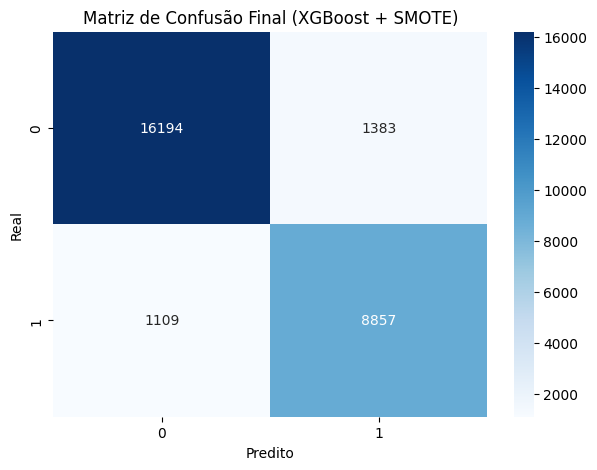

In [2]:
import pandas as pd
import numpy as np
import itertools
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, 
    confusion_matrix, roc_auc_score, balanced_accuracy_score
)
from imblearn.over_sampling import SMOTE

param_grid = {
    'n_estimators':    [75, 100, 200],
    'max_depth':       [5, 6, 7],
    'learning_rate':   [0.05, 0.1, 0.2],
}

keys = list(param_grid.keys())
values = list(param_grid.values())
best_f1 = -1
best_params = None
logo = LeaveOneGroupOut()

for combo in itertools.product(*values):
    params = dict(zip(keys, combo))
    current_f1_scores = []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        
        X_train_proc = imputer.fit_transform(scaler.fit_transform(X_train))
        X_test_proc = imputer.transform(scaler.transform(X_test))

        smote = SMOTE(random_state=42)
        X_train_sm, y_train_sm = smote.fit_resample(X_train_proc, y_train)

        # Treino
        model = XGBClassifier(**params, eval_metric='logloss', random_state=42)
        model.fit(X_train_sm, y_train_sm)
        
        y_pred = model.predict(X_test_proc)
        current_f1_scores.append(f1_score(y_test, y_pred, zero_division=0))

    mean_f1 = np.mean(current_f1_scores)
    if mean_f1 > best_f1:
        best_f1 = mean_f1
        best_params = params
        print(f"Novo melhor F1: {best_f1:.3f} -> {best_params}")

print("\n" + "="*50)
print("AVALIAÇÃO FINAL DETALHADA")
print("="*50)

all_y_true = []
all_y_pred = []
all_y_probs = []
group_stats = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    scaler = StandardScaler()
    imputer = SimpleImputer(strategy='mean')
    X_train_proc = imputer.fit_transform(scaler.fit_transform(X_train))
    X_test_proc = imputer.transform(scaler.transform(X_test))
    
    smote = SMOTE(random_state=42)
    X_train_sm, y_train_sm = smote.fit_resample(X_train_proc, y_train)

    final_model = XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
    final_model.fit(X_train_sm, y_train_sm)
    
    y_pred = final_model.predict(X_test_proc)
    y_prob = final_model.predict_proba(X_test_proc)[:, 1]

    all_y_true.extend(y_test)
    all_y_pred.extend(y_pred)
    all_y_probs.extend(y_prob)
    group_stats.append(f1_score(y_test, y_pred, zero_division=0))

print(classification_report(all_y_true, all_y_pred))
print(f"ROC-AUC: {roc_auc_score(all_y_true, all_y_probs):.3f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(all_y_true, all_y_pred):.3f}")
print(f"Desvio Padrão F1 entre Grupos: {np.std(group_stats):.3f}")

plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(all_y_true, all_y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão Final (XGBoost + SMOTE)')
plt.ylabel('Real')
plt.xlabel('Predito')
plt.show()

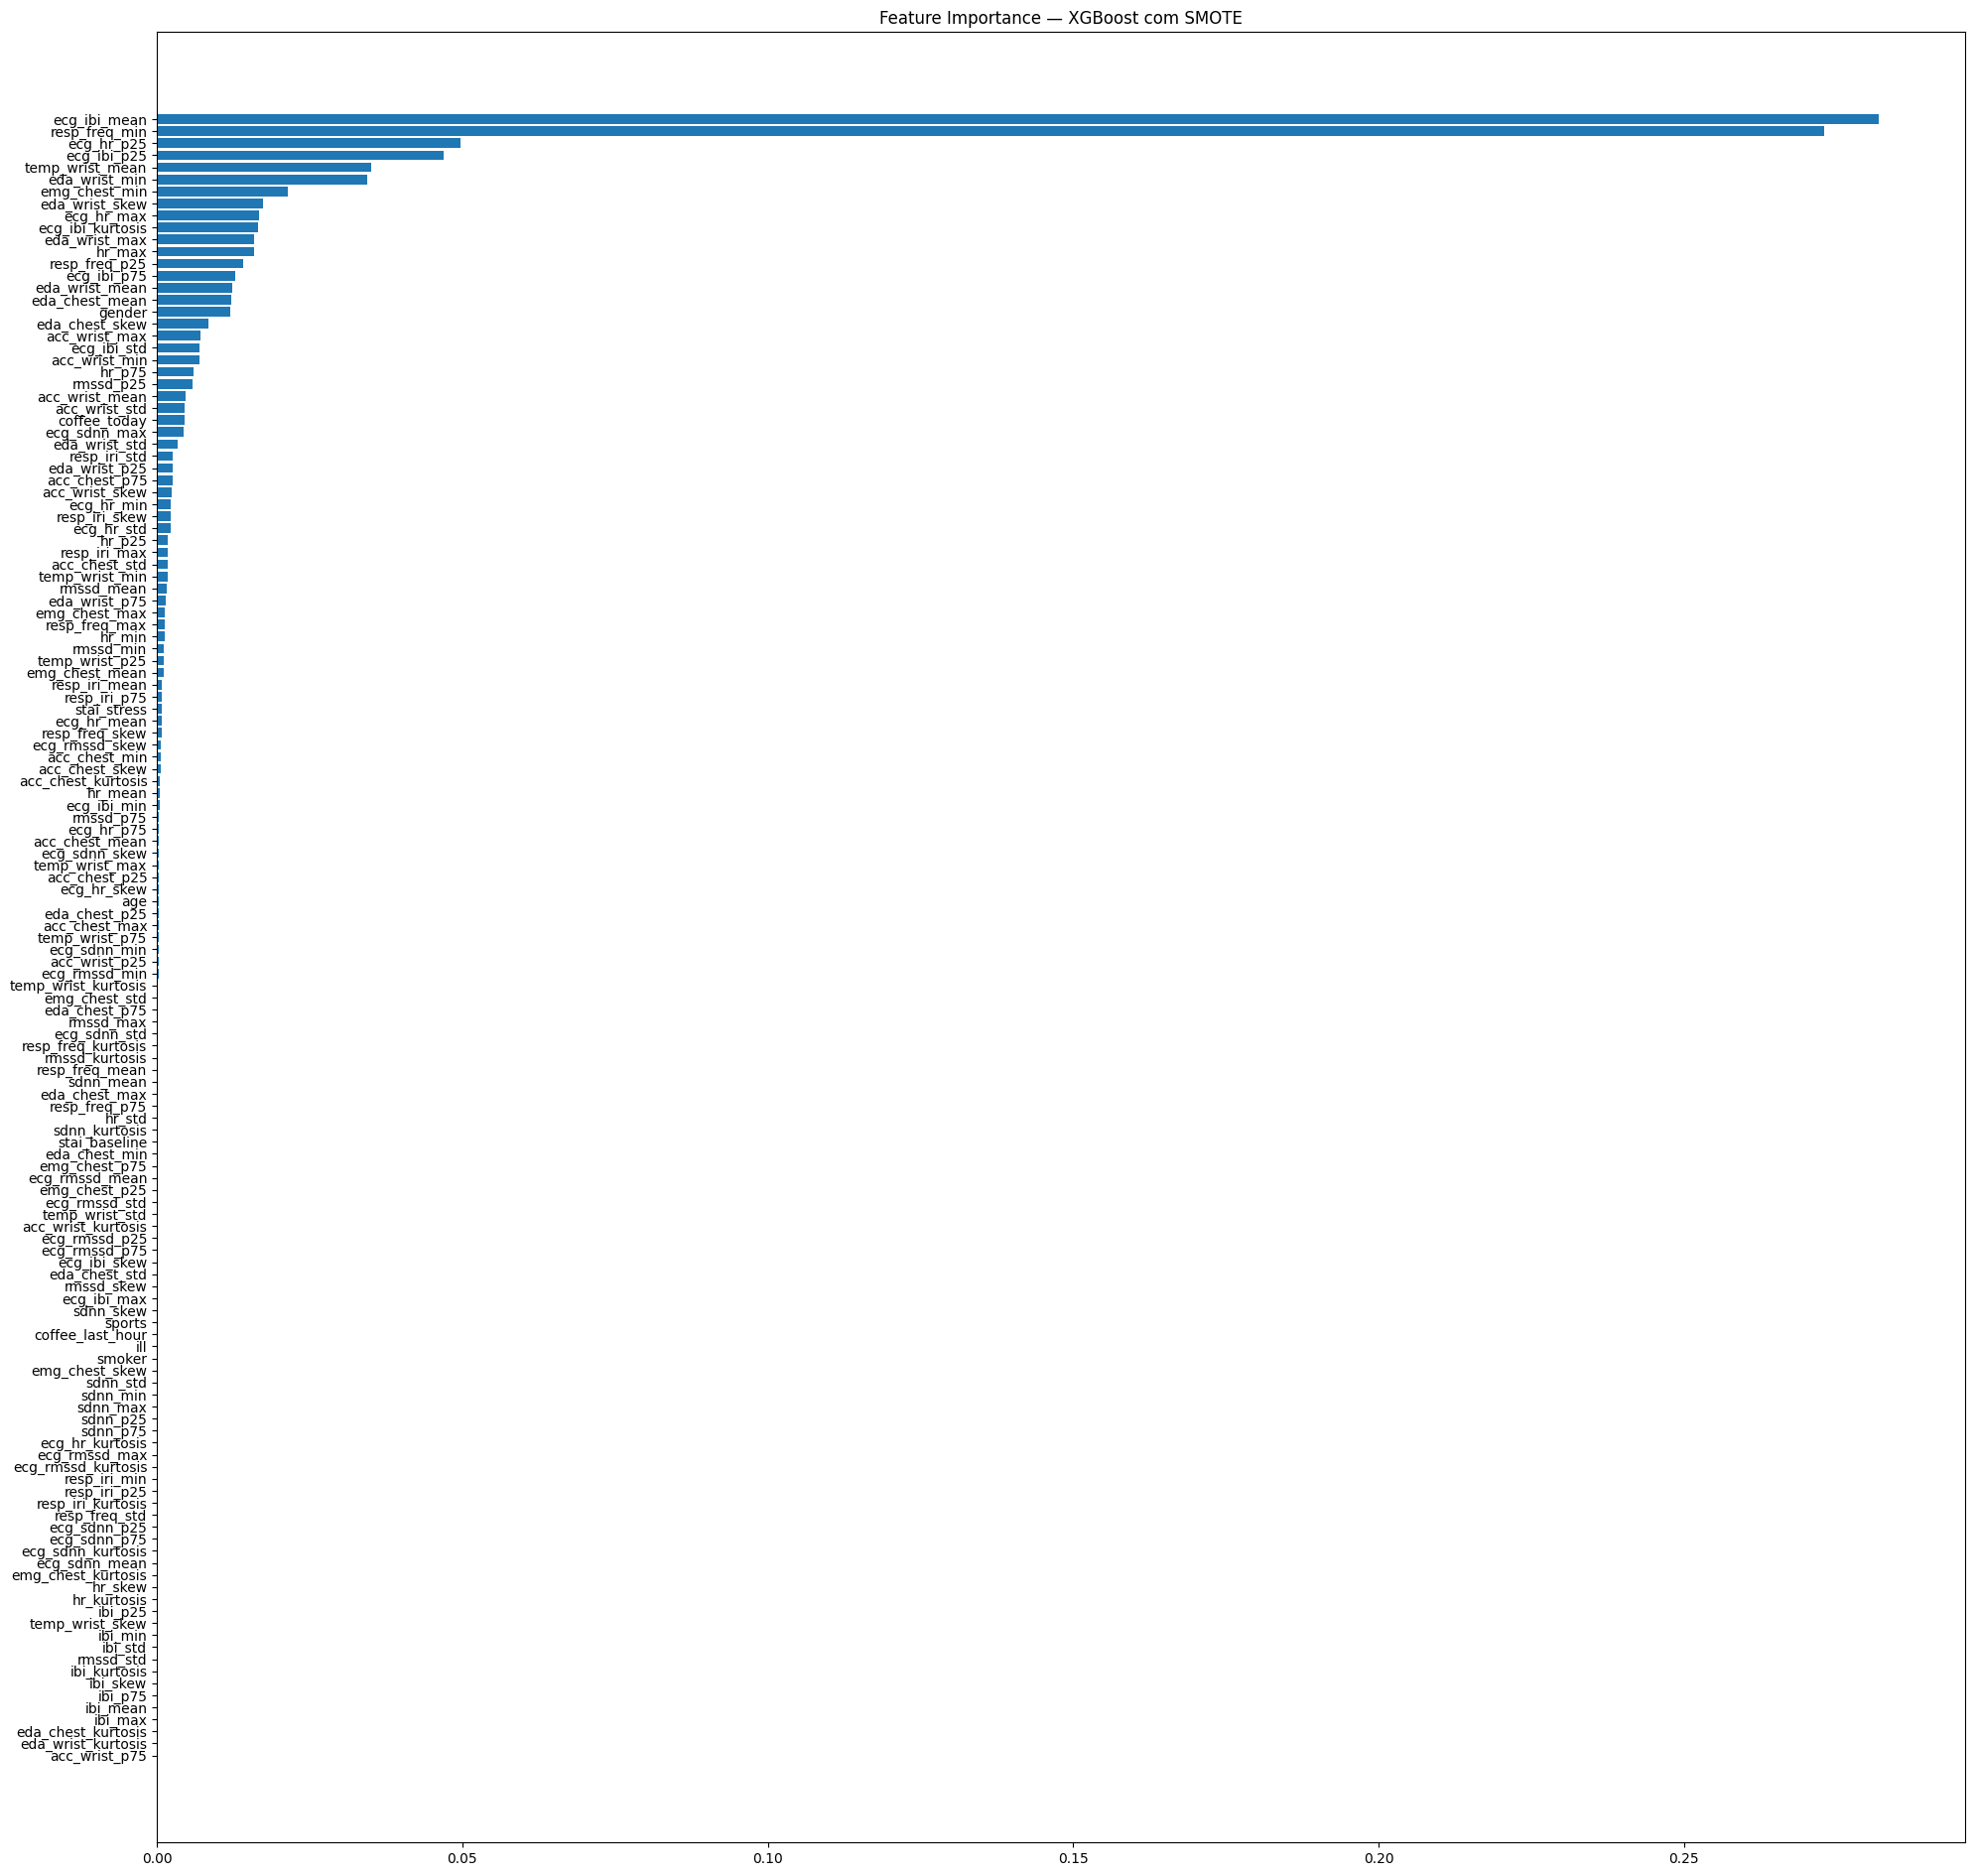

In [3]:
importances = model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(20, 19))
plt.barh(np.array(feature_cols)[indices], importances[indices])
plt.title("Feature Importance — XGBoost com SMOTE")
plt.tight_layout()
plt.show()

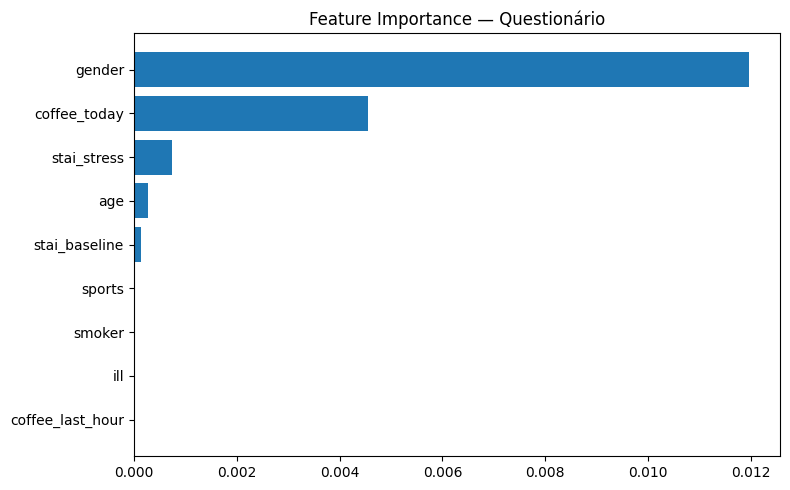

In [4]:
quest_cols = ['age', 'gender', 'coffee_today', 'coffee_last_hour', 'sports', 'smoker', 'ill', 'stai_baseline', 'stai_stress']

quest_indices = [list(feature_cols).index(c) for c in quest_cols]

quest_importances = model.feature_importances_[quest_indices]

indices = np.argsort(quest_importances)

plt.figure(figsize=(8, 5))
plt.barh(np.array(quest_cols)[indices], quest_importances[indices])
plt.title("Feature Importance — Questionário")
plt.tight_layout()
plt.show()

# Modelo LightGBM

1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.



Melhores Parâmetros encontrados: {'n_estimators': 305, 'max_depth': 4, 'learning_rate': 0.19503165674949738, 'num_leaves': 37, 'min_child_samples': 30, 'subsample': 0.6537551310524808, 'colsample_bytree': 0.8522263467378263}

Estatísticas FINAIS - LIGHTGBM + SMOTE
              precision    recall  f1-score   support

    Negativo       0.96      0.91      0.94     17577
    Positivo       0.86      0.94      0.90      9966

    accuracy                           0.92     27543
   macro avg       0.91      0.93      0.92     27543
weighted avg       0.93      0.92      0.92     27543

ROC-AUC Agregado:      0.979
Balanced Accuracy:     0.925
Desvio Padrão F1 (LOGO): 0.114


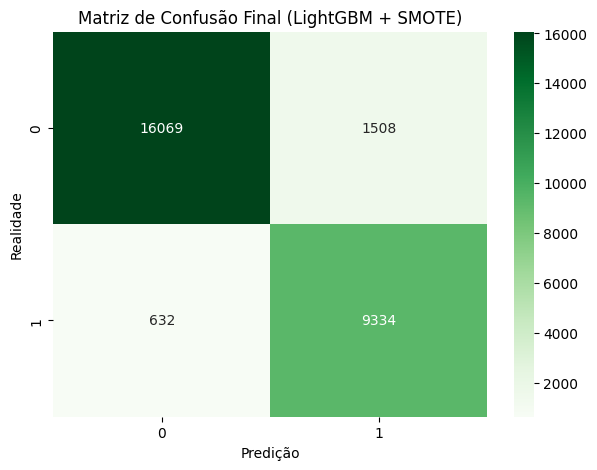

In [5]:
import pandas as pd
import numpy as np
import warnings
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, 
    confusion_matrix, roc_auc_score, balanced_accuracy_score
)
from imblearn.over_sampling import SMOTE

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')
logo = LeaveOneGroupOut()

def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.2),
        'num_leaves':        trial.suggest_int('num_leaves', 31, 127),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
    }
    
    f1_scores = []
    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_tr = imputer.fit_transform(scaler.fit_transform(X_train))
        X_te = imputer.transform(scaler.transform(X_test))

        smote = SMOTE(random_state=42)
        X_train_sm, y_train_sm = smote.fit_resample(X_tr, y_train)

        model = LGBMClassifier(**params, device='gpu', random_state=42, verbose=-1)
        model.fit(X_train_sm, y_train_sm)
        y_pred = model.predict(X_te)
        f1_scores.append(f1_score(y_test, y_pred, zero_division=0))

    return np.mean(f1_scores)

study_smote = optuna.create_study(direction='maximize')
study_smote.optimize(objective, n_trials=500) 

best_params = study_smote.best_params
print(f"\nMelhores Parâmetros encontrados: {best_params}")

all_y_true = []
all_y_pred = []
all_y_probs = []
group_f1_scores = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    scaler = StandardScaler()
    imputer = SimpleImputer(strategy='mean')
    X_train_s = imputer.fit_transform(scaler.fit_transform(X_train))
    X_test_s  = imputer.transform(scaler.transform(X_test))

    smote = SMOTE(random_state=42)
    X_train_sm, y_train_sm = smote.fit_resample(X_train_s, y_train)

    model = LGBMClassifier(**best_params, device='gpu', random_state=42, verbose=-1)
    model.fit(X_train_sm, y_train_sm)
    
    all_y_true.extend(y_test)
    all_y_pred.extend(model.predict(X_test_s))
    all_y_probs.extend(model.predict_proba(X_test_s)[:, 1])
    group_f1_scores.append(f1_score(y_test, all_y_pred[-len(y_test):], zero_division=0))

print("\n" + "="*50)
print("Estatísticas FINAIS - LIGHTGBM + SMOTE")
print("="*50)
print(classification_report(all_y_true, all_y_pred, target_names=['Negativo', 'Positivo']))

print(f"ROC-AUC Agregado:      {roc_auc_score(all_y_true, all_y_probs):.3f}")
print(f"Balanced Accuracy:     {balanced_accuracy_score(all_y_true, all_y_pred):.3f}")
print(f"Desvio Padrão F1 (LOGO): {np.std(group_f1_scores):.3f}")

plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(all_y_true, all_y_pred), annot=True, fmt='d', cmap='Greens')
plt.title('Matriz de Confusão Final (LightGBM + SMOTE)')
plt.ylabel('Realidade')
plt.xlabel('Predição')
plt.show()

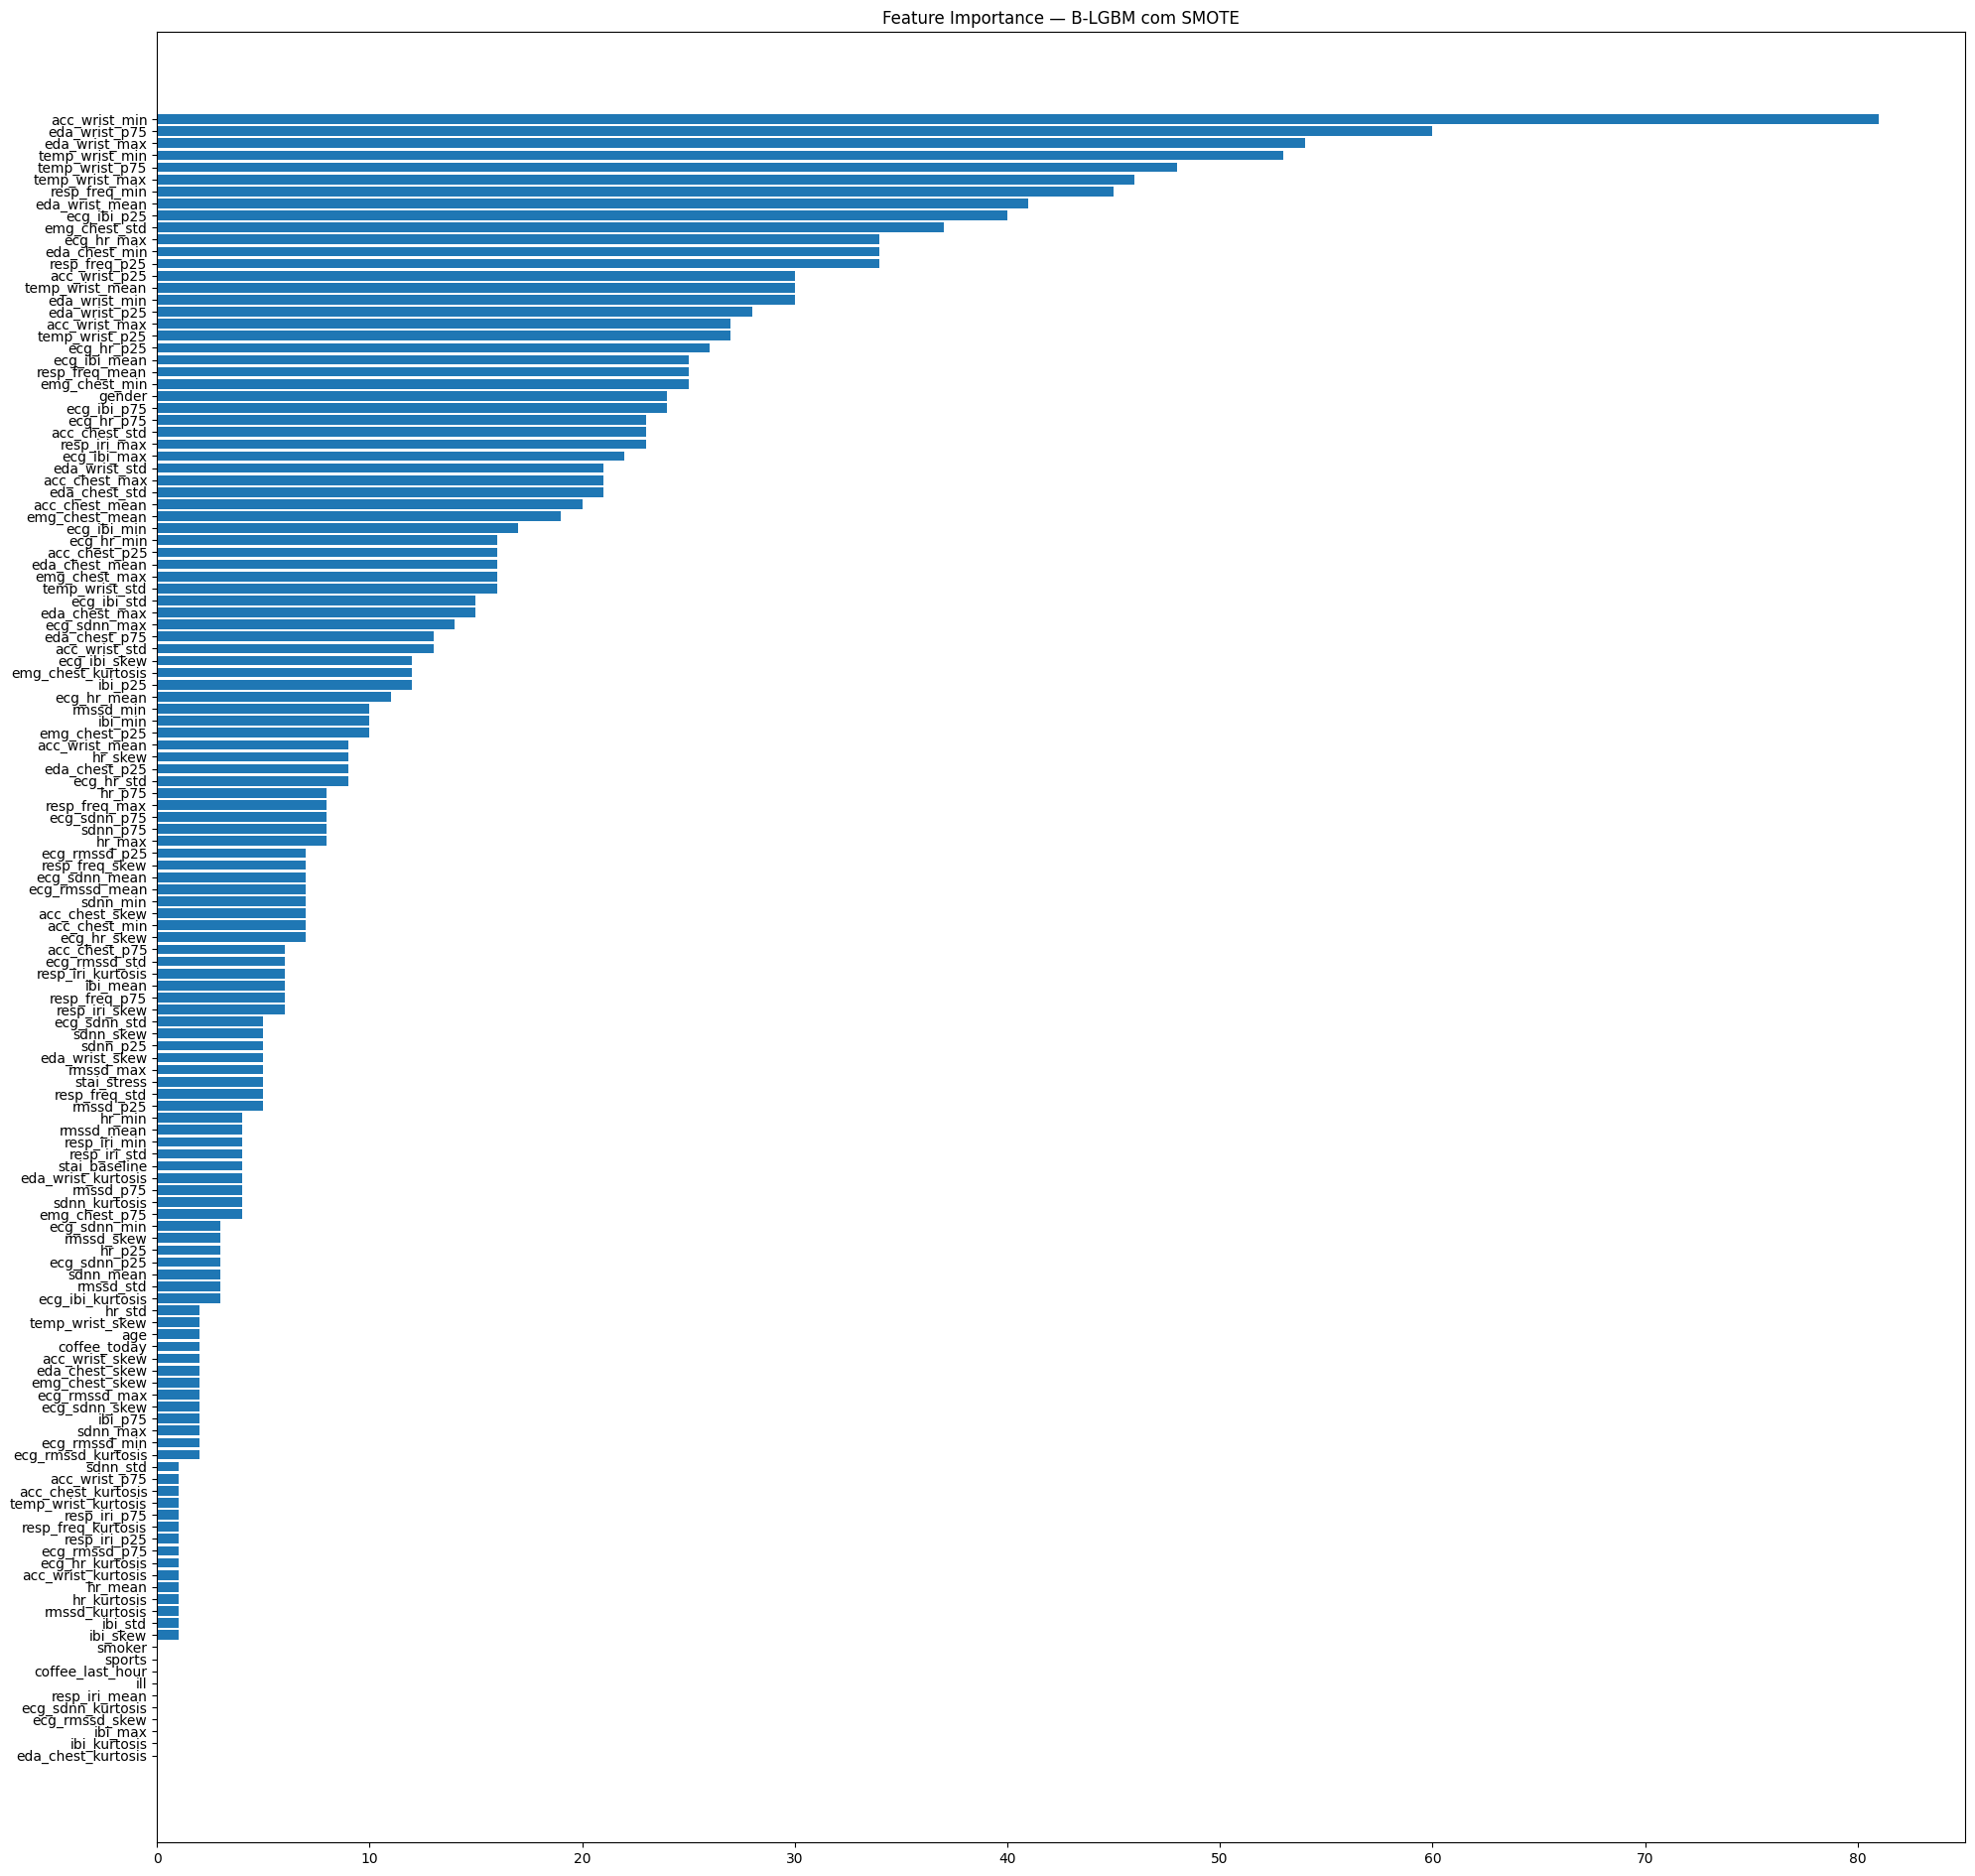

In [6]:
importances = model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(20, 19))
plt.barh(np.array(feature_cols)[indices], importances[indices])
plt.title("Feature Importance — B-LGBM com SMOTE")
plt.tight_layout()
plt.show()

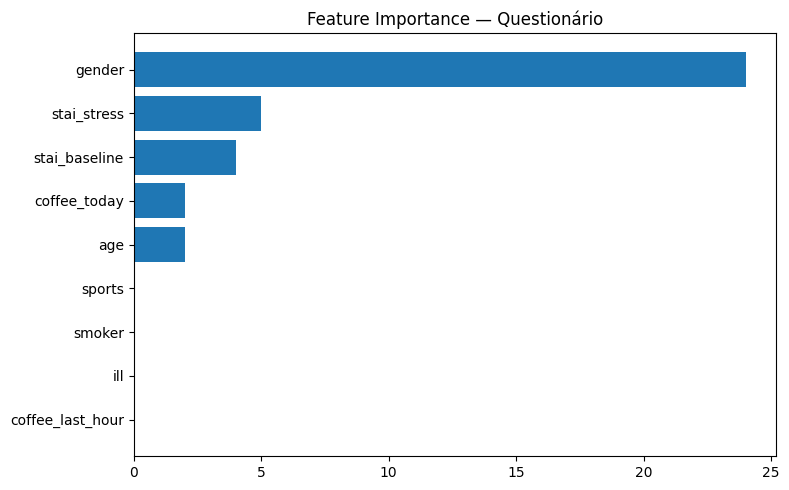

In [7]:
quest_cols = ['age', 'gender', 'coffee_today', 'coffee_last_hour', 'sports', 'smoker', 'ill', 'stai_baseline', 'stai_stress']

quest_indices = [list(feature_cols).index(c) for c in quest_cols]

quest_importances = model.feature_importances_[quest_indices]

indices = np.argsort(quest_importances)

plt.figure(figsize=(8, 5))
plt.barh(np.array(quest_cols)[indices], quest_importances[indices])
plt.title("Feature Importance — Questionário")
plt.tight_layout()
plt.show()